In [1]:
import sys
import os
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy as sp
from sklearn.cluster import DBSCAN
from pyteomics import parser as peptide_parser

from modification_dictionary import aa_comp_custom
# Use explicit imports for clarity and to avoid circular dependencies
from classes_spectrometry import (
    MSExperiment, MassSpectrum, TargetPeptide, PeptidePeak, AnalysisResults,
    GroupedExperiments, interpolate_uneven_data
)

In [51]:

def grouped_find_ms_peaks_targeted_ms1(spectra:list, experiments:list, target_peptide,
                                        mz_range=[400,2000],
                                        rt_range=[4,12],
                                    mz_boundaries: float=2,
                                    time_boundaries=0.05,
                                    interpolation_distance=0.01,
                                    distance_peaks=0.1,
                                    min_peak_width=0.05,
                                    max_peak_width=0.4,
                                    filtered:bool=False, **kwargs):
    ########### LOOP OVER SPECTRA/EXPERIMENTS
    replicates = {
        "replicate":[],
        "spectrum":[],
        "experiment":[],
        "data":[]
    }

    for i, (spectrum, experiment) in enumerate(zip(spectra, experiments)):
        replicates["replicate"].append(i)
        replicates["spectrum"].append(spectrum)
        replicates["experiment"].append(experiment)


        # we first look at the isotopologues and try to find matches in the MS1
        all_chromatograms = []
        for i in range(len(target_peptide.isotopologues["name"])):
            # we call the spectrum's get_extracted_compound_chromatogram function
            chromatogram = spectrum.get_extracted_compound_chromatogram(target_peptide.isotopologues["mass"][i], filtered=filtered, tolerance_ppm=20, mz_range=mz_range, rt_range=rt_range)
            # we rename the index to be the retention time in seconds
            if chromatogram is not None:
                chromatogram.set_index('time')
                chromatogram['isotopologue'] = target_peptide.isotopologues["name"][i]
                all_chromatograms.append(chromatogram)
            elif chromatogram is None:
                chromatogram = spectrum.get_extracted_compound_chromatogram(target_peptide.isotopologues["mass"][i], filtered=filtered, tolerance_ppm=20, mz_range=[mz_range[0]-5, mz_range[1]+5], rt_range=rt_range)
                chromatogram.set_index('time')
                chromatogram['isotopologue'] = target_peptide.isotopologues["name"][i]
                all_chromatograms.append(chromatogram)
        if not all_chromatograms:
            return []
        # we concatenate all the chromatograms into a single dataframe
        total_chromatogram = pd.concat(all_chromatograms)
        # we display the total chromatogram
        total_chromatogram = total_chromatogram.sort_values(by=['time'])

        # we look what the unique charges are
        unique_charges = total_chromatogram['charge'].unique()
        # we sort the charges
        unique_charges = np.sort(unique_charges)

        data_dict = {
            "charge":[],
            "iso":[],
            "eic":[],
            "eic_intp":[],
            "peak_rts":[],
            "peak_infos":[]
        }

        # we generate PeptidePeak objects for each cluster center
        peptide_peaks = []
        for charge in unique_charges:
            # we check the number of points for this charge
            charge_chromatogram = total_chromatogram[total_chromatogram['charge'] == charge]
            if len(charge_chromatogram) < 10:
                continue
            # we check that all the required isotopologues are present, that is all the target_peptide.isotopologues["name"] values are also in the charge_chromatogram['isotopologue'] column values
            required_isotopologues = target_peptide.isotopologues["name"]
            required_isotopologues_mz =  [(mass_topo + charge * 1.007276466812) / charge for mass_topo in target_peptide.isotopologues["mass"]]
            bounds_mz_min = min(required_isotopologues_mz) - mz_boundaries / charge
            bounds_mz_max = max(required_isotopologues_mz) + mz_boundaries / charge

            ################ EIC DATA HANDLING AND INTERPOLATION
            # we transform the dataframe so that the columns are the isotopologues and the index is the retention time, the values are the intensities
            charge_chromatogram = charge_chromatogram.pivot_table(index='time', columns='isotopologue',
                                                            values='intensity_array',
                                                            aggfunc='sum', fill_value=0)
            charge_chromatogram['total_intensity'] = charge_chromatogram.sum(axis=1)
            # we sort the index
            charge_chromatogram = charge_chromatogram.sort_index()

            # we make a new array of time points from the minimum to the maximum with a step of time_diffs
            new_time_points = np.arange(charge_chromatogram.index.min(), charge_chromatogram.index.max(), interpolation_distance)
            # we use the numpy interpolate function to interpolate the data
            interpolated_charge_chromatogram = pd.DataFrame(index=new_time_points)

            for iso in required_isotopologues:
                # we check that the column with the iso exists and is not zero
                if iso in charge_chromatogram.columns:
                    if charge_chromatogram[iso].sum() != 0:

                        # we get the index as a numpy array
                        index_np = charge_chromatogram.index.to_numpy()
                        # we get the signal as a numpy array
                        signal_np = charge_chromatogram[iso].to_numpy()
                        new_signal_array = np.interp(new_time_points, index_np, signal_np)
                        interpolated_charge_chromatogram[iso] = new_signal_array
                else:
                    # if the isotopologue is not present, we fill the column with zeros
                    interpolated_charge_chromatogram[iso] = 0
            charge_chromatogram = charge_chromatogram.sort_index()
            interpolated_charge_chromatogram = interpolated_charge_chromatogram.sort_index()

            #################### PEAK PICKING

            # we scale the peak parameters for peak picking to the interpolated data samples
            peak_widths = [round(min_peak_width/interpolation_distance), round(max_peak_width/interpolation_distance)]
            distance_in_points = round(distance_peaks/interpolation_distance)

            absolute_noise_threshold = 1000

            for i, iso in enumerate(required_isotopologues):
                # we call find_peaks on the isotopologue intensity
                maximum = interpolated_charge_chromatogram[iso].max()
                peaks_iso_indices, properties_iso = sp.signal.find_peaks(interpolated_charge_chromatogram[iso],
                                                                    rel_height=0.9,
                                                                    height=absolute_noise_threshold,
                                                                    width=peak_widths,
                                                                    distance=distance_in_points,
                                                                    prominence = 0.4
                                                                    )

                peak_rts = interpolated_charge_chromatogram.index[peaks_iso_indices]

                data_dict["charge"].append(int(charge))
                data_dict["iso"].append(str(iso))
                data_dict["eic"].append(charge_chromatogram)
                data_dict["eic_intp"].append(interpolated_charge_chromatogram)
                data_dict["peak_rts"].append(peak_rts.tolist())
                data_dict["peak_infos"].append(properties_iso)

        replicates["data"].append(data_dict)
    return replicates

def group_peaks_from_replicates(replicates, target_peptide, time_boundaries=0.05, mz_boundaries=2.0,distance_peaks=0.1, min_replicates=2):
    '''
    we group the peaks from the different experimental replicates. Real potential peaks are more likely to occur in several replicates at approx the same RT for the same fragment and charge state, while noise peaks are more likely to occur randomly in one replicate and not in the others. So we can use the presence of peaks in multiple replicates at similar RTs as a criterion to filter out noise peaks and keep only the more reliable ones. We can use a clustering algorithm like DBSCAN to group peaks across replicates based on their RT proximity, and then we can keep only the clusters that contain peaks from multiple replicates as our final set of validated peaks.
    We also make sure to cluster the peaks from the same isotopologue together, since they should co-elute and have the same RT, and we can use the presence of a consistent isotopic pattern across replicates as an additional criterion to validate the peaks. For example, if we see a cluster of peaks that includes the expected isotopologues with the correct relative intensities in multiple replicates, we can be more confident that this cluster represents a true signal corresponding to our target peptide, rather than random noise.
    :param replicates: a list of dictionaries, each containing the peak data for a replicate, including the RTs of detected peaks for each isotopologue and charge state
    :param target_peptide: the target peptide
    :param time_boundaries:
    :param distance_peaks:
    :return:
    '''

    # we loop over the charges first, and we group the peaks based on their RT proximity using DBSCAN keeping the clusters that have peaks from multiple replicates and that have the expected isotopologues with the correct relative intensities as the final validated peaks,
    # we also then attempt to cluster/compare over the charge states to see if there are peaks across replicates for several charge states that coincide in terms of the retention time, which is a strong indicator of peptide peaks making the peaks much more likely to be a true hit
    num_reps = len(replicates["replicate"])
    peptide_peaks = []

    # Find all unique charges across all extracted data
    all_charges = set()
    for data_dict in replicates["data"]:
        all_charges.update(data_dict["charge"])

    # Process one charge state at a time
    for charge in sorted(all_charges):
        raw_points = []

        # 1. Gather all peaks for this specific charge state across all replicates
        for rep_idx in range(num_reps):
            data_dict = replicates["data"][rep_idx]

            for row_idx, (ch, iso, rts, info) in enumerate(zip(data_dict["charge"], data_dict["iso"], data_dict["peak_rts"], data_dict["peak_infos"])):
                if ch != charge:
                    continue
                for peak_flat_idx, rt in enumerate(rts):
                    raw_points.append({
                        "rt": rt,
                        "rep_idx": rep_idx,
                        "iso": iso,
                        "row_idx": row_idx,              # Links back to the correct dataframe row
                        "peak_flat_idx": peak_flat_idx   # Links back to correct left_ips/right_ips
                    })

        if not raw_points:
            continue

        # Convert to numpy array for clustering
        flattened_rts = np.array([p["rt"] for p in raw_points]).reshape(-1, 1)

        # 2. Run DBSCAN across all replicates/isotopologues for this charge
        # minimal samples for scan is the number of required replictaes times the number of expected isotopologues
        dbscan_minimum = min_replicates*len(target_peptide.isotopologues["name"])
        db = DBSCAN(eps=distance_peaks, min_samples=dbscan_minimum).fit(flattened_rts)
        labels = db.labels_

        # 3. Process each cluster found
        for label in set(labels):
            if label == -1:
                continue  # Ignore noise points

            # Filter our raw points belonging to this cluster
            cluster_indices = np.where(labels == label)[0]
            cluster_points = [raw_points[idx] for idx in cluster_indices]

            # --- QC CHECK 1: Replicate Count Verification ---
            replicates_in_cluster = set(p["rep_idx"] for p in cluster_points)
            if len(replicates_in_cluster) < min_replicates:
                continue

            # --- QC CHECK 2: Monoisotopic Presence (Optional but recommended) ---
            # isos_in_cluster = set(p["iso"] for p in cluster_points)
            # if "monoisotopic" not in isos_in_cluster: continue

            # Calculate the global reference center for this cluster across all replicates
            cluster_rts = [p["rt"] for p in cluster_points]
            global_center = np.median(cluster_rts)

            # 4. Generate PeptidePeak objects for each contributing replicate
            for rep_idx in replicates_in_cluster:
                spectrum = replicates["spectrum"][rep_idx]
                experiment = replicates["experiment"][rep_idx]
                data_dict = replicates["data"][rep_idx]

                # Filter points belonging just to this specific replicate within the cluster
                rep_points = [p for p in cluster_points if p["rep_idx"] == rep_idx]

                rep_rts = []
                rep_starts = []
                rep_ends = []

                # Grab chromatogram reference from the first available point entry
                sample_row = rep_points[0]["row_idx"]
                interpolated_charge_chromatogram = data_dict["eic_intp"][sample_row]

                # Fallback bounds limits to keep indexing safe
                max_idx = len(interpolated_charge_chromatogram.index) - 1

                for p in rep_points:
                    rep_rts.append(p["rt"])
                    info = data_dict["peak_infos"][p["row_idx"]]
                    p_idx = p["peak_flat_idx"]

                    # Convert float ips tracking to rounded integer index positions
                    left_idx = np.clip(int(round(info["left_ips"][p_idx])), 0, max_idx)
                    right_idx = np.clip(int(round(info["right_ips"][p_idx])), 0, max_idx)

                    rep_starts.append(interpolated_charge_chromatogram.index[left_idx])
                    rep_ends.append(interpolated_charge_chromatogram.index[right_idx])

                # Compute replicate-specific consensus metrics
                median_peak_start = float(np.median(rep_starts))
                median_peak_end = float(np.median(rep_ends))
                center = float(np.median(rep_rts))

                # Extract target boundaries for raw apex generation
                required_isotopologues_mz = [(mass_topo + charge * 1.007276466812) / charge for mass_topo in target_peptide.isotopologues["mass"]]
                bounds_mz_min = min(required_isotopologues_mz) - mz_boundaries / charge
                bounds_mz_max = max(required_isotopologues_mz) + mz_boundaries / charge

                raw_apex_data = spectrum.get_raw_data(mz_range=[bounds_mz_min, bounds_mz_max],
                                                     rt_range=[median_peak_start, median_peak_end], filtered=False)

                # Gather MS2 precursor spectra hits
                ms2_matches = []
                for iso_tgt_mass in target_peptide.isotopologues["mass"]:
                    potential_ms2_precursors = spectrum.get_ms2_precursor_matches(
                        mass=iso_tgt_mass, charge=charge, rt_range=[median_peak_start, median_peak_end],
                        tolerance=20, tolerance_unit="ppm"
                    )
                    if potential_ms2_precursors is not None and not potential_ms2_precursors.empty:
                        ms2_matches.append(potential_ms2_precursors)

                ms2_matches_df = pd.concat(ms2_matches) if ms2_matches else pd.DataFrame()

                # Instantiate and process metrics using your framework API
                peptide_peak = PeptidePeak(experiment=experiment, target=target_peptide,
                                           charge=charge, rt=center, raw_apex=raw_apex_data,
                                           extracted=interpolated_charge_chromatogram, ms2_data=ms2_matches_df,
                                           rt_start=median_peak_start, rt_end=median_peak_end)

                peptide_peak.cluster_label = int(label)
                peptide_peak.cluster_id = f"charge_{charge}_cluster_{label}"
                peptide_peak.replicate_id = int(rep_idx)

                peptide_peak.integrate_peak()
                _ = peptide_peak.process_and_find_peaks(snr_level=2, prominence=0.5, height=1000,
                                                       settings_1=("bin", "find_peaks_cwt"),
                                                       settings_2=("autopique", "find_peaks"), bin_size=0.001)

                # Execute QA tests native to object instance
                peptide_peak.validate_ms1_pattern(tolerance_ppm=10)
                peptide_peak.match_ms2_fragmentation(tolerance=20, tolerance_unit="ppm")
                peptide_peak.process_ms1_quality()
                peptide_peak.calculate_quality_score()

                if peptide_peak.best_matches is not None and not peptide_peak.best_matches.empty:
                    peptide_peaks.append(peptide_peak)

    return peptide_peaks

def extract_true_peptide_peaks(peptide_peaks, score_threshold=0.7, min_good_samples=2, area_ratio=0.30):
    if not peptide_peaks:
        return []

    # 1. Build a map to count high-quality scores per cluster group
    cluster_scores = {}
    for p in peptide_peaks:
        group_key = (p.charge, p.cluster_id)
        if group_key not in cluster_scores:
            cluster_scores[group_key] = 0
        if getattr(p, 'quality_score', 0) >= score_threshold:
            cluster_scores[group_key] += 1

    # Filter list: Keep objects only if their cluster group achieved enough high scores
    validated_peaks = [p for p in peptide_peaks if cluster_scores[(p.charge, p.cluster_id)] >= min_good_samples]

    # 2. Find the reference maximum area per Replicate + Charge combo
    rep_charge_max_area = {}
    for p in validated_peaks:
        rep_key = (p.replicate_id, p.charge)
        peak_area = getattr(p, 'trapz_area', 0)  # Adjust if area is nested under another attribute

        if rep_key not in rep_charge_max_area:
            rep_charge_max_area[rep_key] = 0.0
        if peak_area > rep_charge_max_area[rep_key]:
            rep_charge_max_area[rep_key] = peak_area

    # 3. Assign the significance flag directly to the object attributes
    for p in validated_peaks:
        rep_key = (p.replicate_id, p.charge)
        max_ref_area = rep_charge_max_area[rep_key]
        peak_area = getattr(p, 'trapz_area', 0)

        # Protect against division by zero if max_area is somehow 0
        if max_ref_area > 0:
            p.significant = bool(peak_area >= (area_ratio * max_ref_area))
        else:
            p.significant = False

    return validated_peaks

In [52]:
# we load several experiments from a list of pickle files
experiment_pickle_list = [r"C:\Users\jordant\PycharmProjects\LCMS_RiPP\output_data_flasks\TJ-C-560_TJ-C-593_unique_sample_1\unique_sample_1_wild_type_hyella_peptides_experiment.pkl",
                          r"C:\Users\jordant\PycharmProjects\LCMS_RiPP\output_data_flasks\TJ-C-560_TJ-C-593_unique_sample_2\unique_sample_2_wild_type_hyella_peptides_experiment.pkl",
                          r"C:\Users\jordant\PycharmProjects\LCMS_RiPP\output_data_flasks\TJ-C-560_TJ-C-593_unique_sample_3\unique_sample_3_wild_type_hyella_peptides_experiment.pkl"]
# we open all the pickels and make a list of all the objects
exp_objs = []
spec_objs = []
for item in experiment_pickle_list:
    with open(item, "rb") as f:
        experiment = pickle.load(f)
        exp_objs.append(experiment)
        spectrum = MassSpectrum(
            mzml_path=experiment.mzml_path,
            output_path=experiment.output_path,
            spectrum_id=experiment.spectrum_id
        )
        spectrum.load(minimum_intensity=1000)
        spec_objs.append(spectrum)



Spectral data for 'unique_sample_1_wild_type_hyella_peptides' successfully loaded from cache.
Spectral data for 'unique_sample_2_wild_type_hyella_peptides' successfully loaded from cache.
Spectral data for 'unique_sample_3_wild_type_hyella_peptides' successfully loaded from cache.


In [53]:
# we get the spectrum from the experiment
target = experiment.target_peptides[3]
# we call the find_ms_peaks_targeted_ms1 function
replicates = grouped_find_ms_peaks_targeted_ms1(spec_objs, exp_objs, target, rt_range=[3,12], mz_range=[400,2000], mz_boundaries=2, time_boundaries=0.02, interpolation_distance=0.01, distance_peaks=0.02, min_peak_width=0.02, max_peak_width=0.4, filtered=False)
peptide_peaks = group_peaks_from_replicates(replicates, target, time_boundaries=0.02, mz_boundaries=2.0, distance_peaks=0.02, min_replicates=2)
validated_peaks = extract_true_peptide_peaks(peptide_peaks, score_threshold=0.7, min_good_samples=2,area_ratio=0.30)

C:\Users\jordant\AppData\Local\anaconda3\envs\lcms\Lib\site-packages\scipy\signal\_peak_finding.py:1193: RuntimeWarning: divide by zero encountered in scalar divide
  snr = abs(cwt[line[0][0], line[1][0]] / noises[line[1][0]])
C:\Users\jordant\AppData\Local\anaconda3\envs\lcms\Lib\site-packages\scipy\signal\_peak_finding.py:1193: RuntimeWarning: invalid value encountered in scalar divide
  snr = abs(cwt[line[0][0], line[1][0]] / noises[line[1][0]])


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(
C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


...

C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(
C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(
C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(
C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(
C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(
C:\Users\jordant\PycharmProjects\LCMS_RiPP\classes_spectrometry.py:723: OptimizeWarning: Covariance of the parameters could not be estimated
  gaussian_params, pcov = sp.optimize.curve_fit(


In [54]:
summary_data = []
for p in validated_peaks:
    summary_data.append({
        "Replicate": p.replicate_id,
        "Cluster": p.cluster_id,
        "Charge": p.charge,
        "Consensus_RT": round(p.rt, 3),
        "RT_Start": round(p.rt_start, 3),
        "RT_End": round(p.rt_end, 3),
        "Peak_Width": round(p.rt_end - p.rt_start, 3),
        "Area": round(p.trapz_area),
        "Has_MS2_Match": not p.ms2_data.empty,
        "Quality_Score": getattr(p, 'quality_score', 'N/A'),
        "Significant": p.significant
    })
df_summary = pd.DataFrame(summary_data)

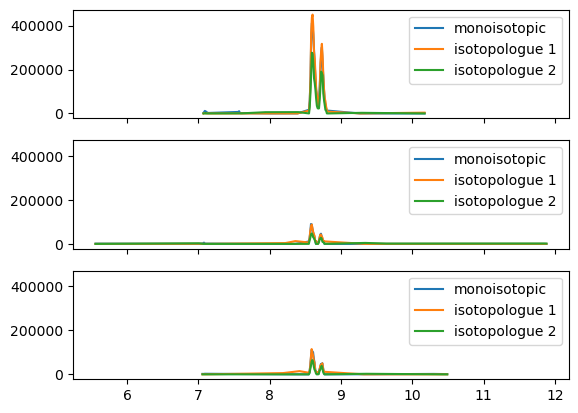

In [25]:
fig, ax = plt.subplots(nrows=3, sharex=True, sharey=True)
for i in range(0,3):
    replicates["data"][i]["eic_intp"][1].plot(ax=ax[i])
